# Telecom Customer Churn: Analysis and Prediction
## 1. Project Overview
An end-to-end, reproducible analysis of customer churn using demographic, registration, provider, geographic, and usage records. The objective is to identify customers at risk of churn and assess whether the available data supports useful retention targeting.

## 2. Business Problem
Retention teams have limited outreach capacity. A useful model should rank likely churners better than random selection, while balancing missed churners (recall) against unnecessary contacts (precision). Churn is the positive class (`1`). Average precision (AP) is the primary ranking metric; ROC-AUC, precision, recall, F1, and confusion matrices provide complementary views.

No churn horizon, observation timestamp, source documentation, or intervention costs are supplied. This is a retrospective benchmark, conditional on every input being available **before** churn. It does not establish causal drivers or production readiness.

### Import libraries


In [1]:
from pathlib import Path
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, accuracy_score, classification_report, precision_recall_curve,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

import hashlib
import json
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from threadpoolctl import threadpool_limits

import json

from sklearn.metrics import make_scorer
import warnings
warnings.filterwarnings("ignore", message=r".*sklearn.utils.parallel.delayed.*", category=UserWarning)


### Configure reproducibility and chart styling

Keep the random seed and display settings consistent throughout the notebook.


In [2]:
RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Python {platform.python_version()} | pandas {pd.__version__} | sklearn {sklearn.__version__}')


Python 3.12.5 | pandas 2.3.3 | sklearn 1.8.0


## 3. Dataset Understanding
Load the CSV relative to the notebook directory. Customer identifiers are keys, not predictors. Postal codes have no documented geographic mapping and are excluded rather than treated as continuous measurements. Usage units and salary currency are unspecified, so charts avoid invented units.

### Load data and validate the schema


In [3]:
DATA_PATH = Path('telecom_churn.csv')
raw_data = pd.read_csv(DATA_PATH)
required_columns = {'customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city',
    'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary',
    'calls_made', 'sms_sent', 'data_used', 'churn'}
assert set(raw_data.columns) == required_columns, 'Unexpected dataset schema.'
assert raw_data['churn'].notna().all() and set(raw_data['churn'].unique()) == {0, 1}
assert raw_data['customer_id'].notna().all() and raw_data['customer_id'].is_unique
print(f'{raw_data.shape[0]:,} customers; {raw_data.shape[1]} columns')


243,553 customers; 14 columns


### Target semantics
The label contains exactly 0 and 1. This project explicitly uses **churn = 1**, stayed = 0; probabilities are taken from the estimator's class-1 column. CSV values alone cannot verify the business semantics. Confirm cancellation/inactivity definition, prediction horizon and observation time with the source owner before operational use.


### Preview customer records


In [4]:
display(raw_data.head())


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


### Check data types, missing values, and category counts


In [5]:
display(pd.DataFrame({'dtype': raw_data.dtypes.astype(str),
    'missing': raw_data.isna().sum(), 'unique_values': raw_data.nunique()}))


,dtype,missing,unique_values
customer_id,int64,0,243553
telecom_partner,object,0,4
gender,object,0,2
age,int64,0,57
state,object,0,28
city,object,0,6
pincode,int64,0,213442
date_of_registration,object,0,1220
num_dependents,int64,0,5
estimated_salary,int64,0,110032


### Summarize numerical features


In [6]:
display(raw_data.describe().T)


,count,mean,std,min,25%,50%,75%,max
customer_id,243553.0,121777.000000,70307.839393,1.0,60889.0,121777.0,182665.0,243553.0
age,243553.0,46.077609,16.444029,18.0,32.0,46.0,60.0,74.0
pincode,243553.0,549501.270541,259808.860574,100006.0,324586.0,548112.0,774994.0,999987.0
num_dependents,243553.0,1.997500,1.414941,0.0,1.0,2.0,3.0,4.0
estimated_salary,243553.0,85021.137839,37508.963233,20000.0,52585.0,84990.0,117488.0,149999.0
calls_made,243553.0,49.010548,29.453556,-10.0,24.0,49.0,74.0,108.0
sms_sent,243553.0,23.945404,14.733575,-5.0,11.0,24.0,36.0,53.0
data_used,243553.0,4993.186025,2942.019547,-987.0,2490.0,4987.0,7493.0,10991.0
churn,243553.0,0.200478,0.400359,0.0,0.0,0.0,0.0,1.0


### Summarize categorical features


In [7]:
display(raw_data.describe(include=['object', 'string']).T)


,count,unique,top,freq
telecom_partner,243553,4,Reliance Jio,61123
gender,243553,2,M,145977
state,243553,28,Uttarakhand,8856
city,243553,6,Chennai,40749
date_of_registration,243553,1220,2023-05-02,200


## 4. Data Cleaning
Negative calls, messages, and data usage are invalid, but cannot safely be interpreted as zero activity. Mark them missing and retain an invalid-value flag. Median imputation is learned inside each model pipeline using training data only. Dates are parsed vectorially; malformed dates become missing. Exact duplicates are audited, and unique customer IDs ensure one record per customer.

These rules are deterministic and do not depend on the target or distribution. No outliers are removed solely because they are extreme.

### Audit missing values, invalid usage, and duplicates


In [8]:
USAGE_COLUMNS = ['calls_made', 'sms_sent', 'data_used']
quality_audit = pd.DataFrame({'missing': raw_data.isna().sum(),
    'negative_usage': [int((raw_data[c] < 0).sum()) if c in USAGE_COLUMNS else 0
                       for c in raw_data.columns]})
display(quality_audit)
print('Exact duplicate rows:', raw_data.duplicated().sum())


,missing,negative_usage
customer_id,0,0
telecom_partner,0,0
gender,0,0
age,0,0
state,0,0
city,0,0
pincode,0,0
date_of_registration,0,0
num_dependents,0,0
estimated_salary,0,0


Exact duplicate rows: 0


### Flag invalid usage and mark it missing

Retain invalid-value flags. Imputation is learned later from training data inside the model pipeline.


In [9]:
clean_data = raw_data.copy()
for column in USAGE_COLUMNS:
    clean_data[f'{column}_invalid'] = (clean_data[column] < 0).astype(int)
    clean_data[column] = clean_data[column].mask(clean_data[column] < 0)


### Parse registration dates and validate numeric ranges


In [10]:
clean_data['date_of_registration'] = pd.to_datetime(
    clean_data['date_of_registration'], format='%Y-%m-%d', errors='coerce')
print('Unparseable registration dates:', clean_data['date_of_registration'].isna().sum())
print('Registration range:', clean_data['date_of_registration'].min(),
      'to', clean_data['date_of_registration'].max())
assert clean_data['age'].dropna().between(0, 110).all()
assert (clean_data[['estimated_salary', 'num_dependents']].dropna() >= 0).all().all()


Unparseable registration dates: 0
Registration range: 2020-01-01 00:00:00 to 2023-05-04 00:00:00


### Preserved holdouts
Keep the existing stratified 60/20/20 split, original row order, seed 42, and split calls unchanged. Save customer IDs for reproducibility. The test set has already been inspected in earlier work: it is **not a fresh independent holdout**. All new choices use training CV; validation selects operating rules. Test results are a descriptive audit of a frozen decision, not a fresh final performance claim. Further experimentation needs a new independent cohort.


### Separate features and target


In [11]:
features = clean_data.drop(columns=['churn', 'customer_id', 'pincode'])
target = clean_data['churn'].astype(int)


### Create stratified training, validation, and test sets

Reserve holdouts before exploration to prevent information leakage.


In [12]:
X_development, X_test, y_development, y_test = train_test_split(
    features, target, test_size=0.20, stratify=target, random_state=RANDOM_STATE)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25, stratify=y_development,
    random_state=RANDOM_STATE)


In [13]:
import hashlib
split_ids = {name: raw_data.loc[x.index, 'customer_id'].tolist()
             for name, x in [('train', X_train), ('validation', X_validation), ('test', X_test)]}
split_path = Path('split_customer_ids.json')
if split_path.exists():
    assert json.loads(split_path.read_text()) == split_ids, 'Split membership changed.'
else:
    split_path.write_text(json.dumps(split_ids))
print('CSV SHA256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
print('Preserved split membership saved and checked.')


CSV SHA256: 57d1a2629cad4c63ddd1aaea51da074f7112274d16d810cee4944ed3827767ae
Preserved split membership saved and checked.


### Verify holdout separation and class balance


In [14]:
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_development.index).isdisjoint(X_test.index)
display(pd.DataFrame([{'split': name, 'customers': len(y), 'churn_rate': y.mean()}
    for name, y in [('Training', y_train), ('Validation', y_validation), ('Test', y_test)]]))


,split,customers,churn_rate
0,Training,146131,0.200478
1,Validation,48711,0.200489
2,Test,48711,0.200468


### Prepare training data for exploration

Explore feature relationships using training customers only.


In [15]:
eda_data = X_train.assign(churn=y_train)


## 5. Exploratory Data Analysis
Inspect class imbalance, usage distributions, customer segments, and provider/geographic relationships. Rates include sample sizes and approximate 95% Wilson intervals; small differences should not be treated as reliable business effects. Geographic fields require source validation: city and state combinations may be inconsistent.

### Inspect class balance and missing usage


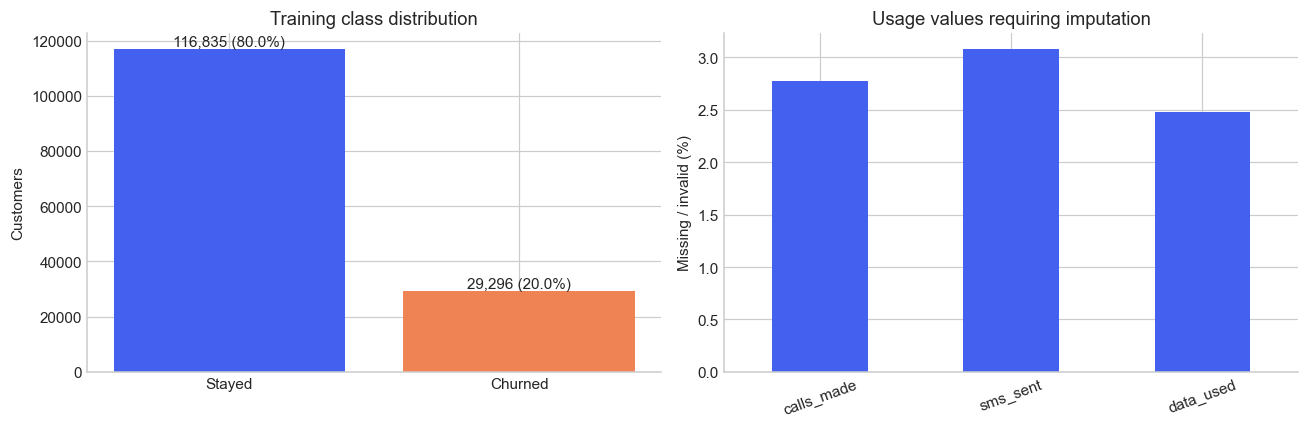

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = y_train.value_counts().sort_index()
axes[0].bar(['Stayed', 'Churned'], counts, color=['#4361ee', '#ef8354'])
axes[0].set(title='Training class distribution', ylabel='Customers')
for i, count in enumerate(counts):
    axes[0].text(i, count, f'{count:,} ({count / len(y_train):.1%})', ha='center', va='bottom')
eda_data[USAGE_COLUMNS].isna().mean().mul(100).plot.bar(ax=axes[1], color='#4361ee')
axes[1].set(title='Usage values requiring imputation', ylabel='Missing / invalid (%)')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()


### Establish the random-ranking AP baseline


In [17]:
print(f'Random-ranking AP baseline: {y_train.mean():.3f}')


Random-ranking AP baseline: 0.200


### Define segment rates and confidence intervals


In [18]:
def segment_summary(data, group):
    result = data.groupby(group, observed=True)['churn'].agg(customers='size', churned='sum')
    result['churn_rate'] = result['churned'] / result['customers']
    z = 1.96
    denominator = 1 + z**2 / result['customers']
    center = (result['churn_rate'] + z**2 / (2 * result['customers'])) / denominator
    half_width = z * np.sqrt(result['churn_rate'] * (1 - result['churn_rate']) /
        result['customers'] + z**2 / (4 * result['customers']**2)) / denominator
    result['lower_95'] = center - half_width
    result['upper_95'] = center + half_width
    return result.sort_values('churn_rate', ascending=False)


### Compare churn across providers and cities


,customers,churned,churn_rate,lower_95,upper_95
telecom_partner,,,,,
Airtel,36426,7417,0.2036,0.1995,0.2078
Reliance Jio,36701,7352,0.2003,0.1963,0.2044
Vodafone,36599,7326,0.2002,0.1961,0.2043
BSNL,36405,7201,0.1978,0.1937,0.2019


,customers,churned,churn_rate,lower_95,upper_95
city,,,,,
Hyderabad,24249,4956,0.2044,0.1994,0.2095
Kolkata,24499,4947,0.2019,0.1969,0.2070
Mumbai,24377,4921,0.2019,0.1969,0.2070
Bangalore,24320,4902,0.2016,0.1966,0.2067
Chennai,24498,4837,0.1974,0.1925,0.2025
Delhi,24188,4733,0.1957,0.1907,0.2007


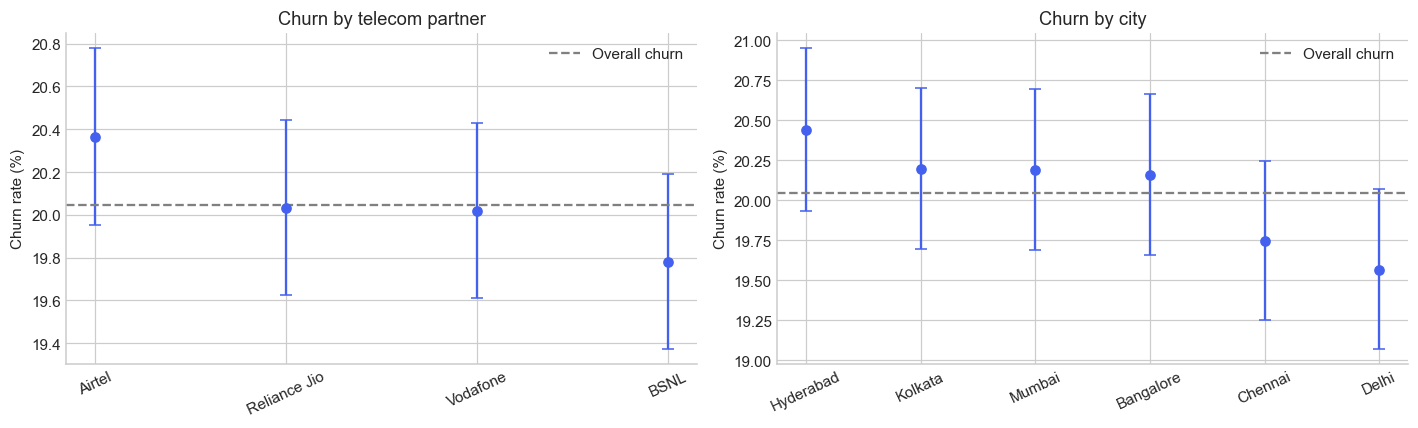

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for axis, group in zip(axes, ['telecom_partner', 'city']):
    summary = segment_summary(eda_data, group)
    display(summary.round(4))
    axis.errorbar(np.arange(len(summary)), summary['churn_rate'] * 100,
        yerr=np.vstack([summary['churn_rate'] - summary['lower_95'],
                        summary['upper_95'] - summary['churn_rate']]) * 100,
        fmt='o', capsize=4, color='#4361ee')
    axis.set_xticks(np.arange(len(summary)), summary.index, rotation=25)
    axis.axhline(y_train.mean() * 100, color='gray', linestyle='--', label='Overall churn')
    axis.set(title=f'Churn by {group.replace("_", " ")}', ylabel='Churn rate (%)')
    axis.legend()
plt.tight_layout(); plt.show()


### Prepare city and provider summary tables


In [20]:
partner_city_rates = eda_data.pivot_table(index='city', columns='telecom_partner',
    values='churn', aggfunc='mean')
partner_city_counts = eda_data.pivot_table(index='city', columns='telecom_partner',
    values='churn', aggfunc='size')


### Visualize city and provider churn rates


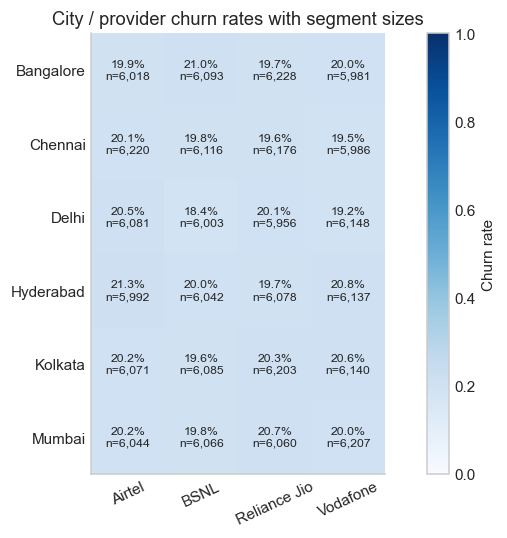

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(partner_city_rates, cmap='Blues', vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(partner_city_rates.columns)), partner_city_rates.columns, rotation=25)
ax.set_yticks(range(len(partner_city_rates.index)), partner_city_rates.index)
for row in range(len(partner_city_rates)):
    for col in range(len(partner_city_rates.columns)):
        ax.text(col, row, f'{partner_city_rates.iloc[row, col]:.1%}\nn={partner_city_counts.iloc[row, col]:,}',
                ha='center', va='center', fontsize=8)
ax.set_title('City / provider churn rates with segment sizes')
fig.colorbar(image, ax=ax, label='Churn rate')
plt.tight_layout(); plt.show()


### Compare numerical distributions by churn


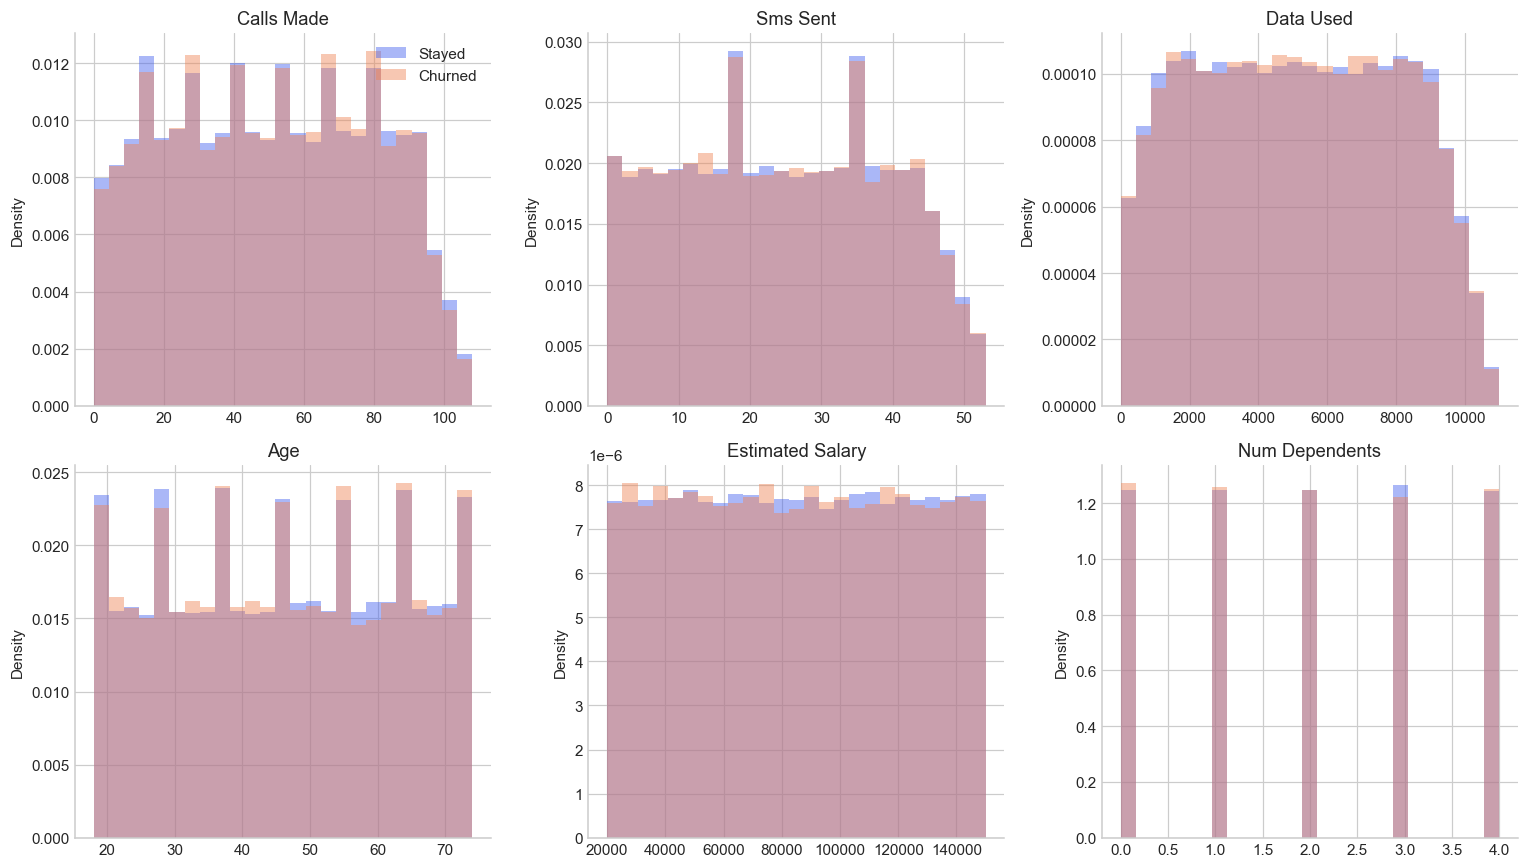

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
plot_columns = USAGE_COLUMNS + ['age', 'estimated_salary', 'num_dependents']
for axis, column in zip(axes.flat, plot_columns):
    for label, color in [(0, '#4361ee'), (1, '#ef8354')]:
        values = eda_data.loc[eda_data['churn'].eq(label), column].dropna()
        axis.hist(values, bins=25, density=True, alpha=0.45,
                  label='Churned' if label else 'Stayed', color=color)
    axis.set(title=column.replace('_', ' ').title(), ylabel='Density')
axes[0, 0].legend()
plt.tight_layout(); plt.show()


### Compare numerical means and medians


In [23]:
display(eda_data.groupby('churn')[plot_columns].agg(['mean', 'median']).round(2))


calls_made        sms_sent        data_used            age         \
            mean median     mean median      mean  median   mean median   
churn                                                                     
0          50.50   50.0     24.8   25.0   5138.27  5128.0  46.08   46.0   
1          50.65   51.0     24.7   25.0   5140.14  5117.0  46.07   46.0   

      estimated_salary          num_dependents         
                  mean   median           mean median  
churn                                                  
0             85090.05  84994.0           2.00    2.0  
1             84787.02  84822.5           1.99    2.0

### Check geographic consistency


In [24]:
display(pd.crosstab(eda_data['city'], eda_data['state']))


state,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chhattisgarh,Goa,Gujarat,Haryana,Himachal Pradesh,Jharkhand,...,Odisha,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal
city,,,,,,,,,,,,,,,,,,,,,
Bangalore,867,909,834,894,858,865,848,875,883,899,...,862,881,907,918,857,837,857,882,831,856
Chennai,854,883,907,892,869,888,906,881,883,884,...,877,887,852,855,838,856,839,878,930,877
Delhi,857,855,885,869,843,848,840,846,882,877,...,857,863,848,864,868,833,907,867,889,814
Hyderabad,882,840,852,815,833,835,885,833,856,893,...,912,867,889,872,850,884,874,851,860,802
Kolkata,820,843,866,857,900,842,868,910,899,827,...,886,842,867,853,873,868,884,885,904,872
Mumbai,832,896,804,893,862,864,856,911,884,867,...,877,847,868,847,854,882,860,890,902,845


### Training-only signal and distribution audit
Quantiles and absolute standardized mean differences describe distribution overlap; single-feature AP/AUC require out-of-fold predictions rather than fitting and scoring the same labels. The model searches below test joint signal. Geography is audited structurally without inventing a city/state mapping.


In [25]:
numeric_audit = []
for column in plot_columns:
    a = eda_data.loc[y_train.eq(0), column].dropna()
    b = eda_data.loc[y_train.eq(1), column].dropna()
    pooled = np.sqrt((a.var() + b.var()) / 2)
    numeric_audit.append({'feature': column, 'absolute_standardized_mean_difference':
        abs(b.mean() - a.mean()) / pooled if pooled else 0,
        'q01': eda_data[column].quantile(.01), 'q50': eda_data[column].median(),
        'q99': eda_data[column].quantile(.99), 'zero_fraction': eda_data[column].eq(0).mean()})
display(pd.DataFrame(numeric_audit).round(5))
display(segment_summary(eda_data, 'gender').round(5))
print('Number of distinct states per city:')
display(eda_data.groupby('city')['state'].nunique())
print('Duplicate predictor records:', X_train.duplicated().sum())


,feature,absolute_standardized_mean_difference,q01,q50,q99,zero_fraction
0,calls_made,0.00527,1.0,50.0,103.00,0.00541
1,sms_sent,0.00695,0.0,25.0,51.00,0.01182
2,data_used,0.00066,174.0,5126.0,10368.99,0.00003
3,age,0.00069,18.0,46.0,74.00,0.00000
4,estimated_salary,0.00807,21296.3,84960.0,148740.00,0.00000
5,num_dependents,0.01008,0.0,2.0,4.00,0.20062


,customers,churned,churn_rate,lower_95,upper_95
gender,,,,,
F,58671,11954,0.20375,0.20051,0.20702
M,87460,17342,0.19828,0.19566,0.20094


Number of distinct states per city:


city
Bangalore    28
Chennai      28
Delhi        28
Hyderabad    28
Kolkata      28
Mumbai       28
Name: state, dtype: int64

Duplicate predictor records: 0


### Interpret descriptive associations


In [26]:
md_note = ('Overlapping distributions and similar segment rates may indicate weak predictive signal. '
           'Associations do not prove salary, network quality, or demographics cause churn.')
display(Markdown(md_note))


Overlapping distributions and similar segment rates may indicate weak predictive signal. Associations do not prove salary, network quality, or demographics cause churn.

## 6. Preprocessing and feature engineering
Imputation, scaling and one-hot encoding are fitted inside each CV pipeline. Identifiers and undocumented postal codes remain excluded. Registration day is a calendar coordinate relative to a fixed origin, **not tenure**; no observation date is available.

Compare raw inputs with missing-usage counts and an inactivity flag (all three usages known and zero). Negative readings remain missing with individual flags. We do not sum calls and SMS: event comparability and measurement windows are undocumented, and data usage has different units. No target aggregates or learned full-data transformations are used.


### Define deterministic customer feature engineering

Create registration and usage features without learning from holdout data.


In [27]:
class CustomerFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, add_features=True):
        self.add_features = add_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        result = X.copy()
        result['registration_day_index'] = (
            result.pop('date_of_registration') - pd.Timestamp('2020-01-01')).dt.days
        if self.add_features:
            usage = result[USAGE_COLUMNS]
            result['usage_missing_count'] = usage.isna().sum(axis=1)
            result['inactive_user'] = np.where(usage.notna().all(axis=1),
                                               usage.eq(0).all(axis=1).astype(float), np.nan)
        return result


### Build numeric and categorical preprocessing pipelines

Numeric features receive median imputation and scaling. Categorical features receive most-frequent imputation and one-hot encoding. Keep these steps inside each pipeline so cross-validation fits them only on its training fold.


In [28]:
def make_model(estimator, add_features=True):
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    preprocessing = ColumnTransformer([
        ('numeric', numeric, make_column_selector(dtype_include=np.number)),
        ('categorical', categorical, make_column_selector(dtype_exclude=np.number))])
    return Pipeline([('features', CustomerFeatures(add_features)),
                     ('preprocessing', preprocessing), ('model', estimator)])


### Check excluded inputs and preview engineered features


In [29]:
assert not {'churn', 'churn_label', 'customer_id', 'pincode'} & set(X_train.columns)
display(CustomerFeatures().fit_transform(X_train).head())


,telecom_partner,gender,age,state,city,num_dependents,estimated_salary,calls_made,sms_sent,data_used,calls_made_invalid,sms_sent_invalid,data_used_invalid,registration_day_index,usage_missing_count,inactive_user
210692,Airtel,F,74,Tamil Nadu,Mumbai,3,37475,3.0,23.0,7698.0,0,0,0,1054,0,0.0
126205,Vodafone,M,25,Odisha,Delhi,1,116943,77.0,32.0,168.0,0,0,0,631,0,0.0
1467,Vodafone,M,25,Kerala,Chennai,2,38956,39.0,24.0,1530.0,0,0,0,7,0,0.0
209788,Airtel,M,63,Himachal Pradesh,Mumbai,4,118717,7.0,20.0,3033.0,0,0,0,1050,0,0.0
56902,BSNL,M,61,Nagaland,Hyderabad,4,142116,60.0,7.0,9164.0,0,0,0,284,0,0.0


## 8. Training-only model search
Compare Logistic Regression, Random Forest, Extra Trees and HistGradientBoosting. Each family receives two randomized configurations per weighting mode (unweighted and balanced), three identical stratified training folds, and AP refitting: **48 CV fits total**, plus refits. Search raw versus justified engineered features inside the pipeline. All training rows are used; search parallelism is bounded. Optional boosting libraries are unnecessary for this modest comparison.

AP is the primary selection metric; ROC-AUC and churn precision/recall/F1/accuracy at 0.5 are supporting metrics. A majority baseline participates in selection. CV variability is descriptive, not a confidence interval after searching. Class weighting is tested, not assumed helpful. No test metrics choose candidates or thresholds.


In [30]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = {'ap': 'average_precision', 'roc_auc': 'roc_auc',
           'precision': make_scorer(precision_score, zero_division=0),
           'recall': make_scorer(recall_score, zero_division=0),
           'f1': make_scorer(f1_score, zero_division=0), 'accuracy': 'accuracy'}
search_specs = {
    'Logistic Regression': (LogisticRegression(max_iter=500),
        {'model__C': [0.01, 0.1, 1, 10]}),
    'Random Forest': (RandomForestClassifier(n_estimators=80, n_jobs=2,
        random_state=RANDOM_STATE), {'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [50, 200], 'model__max_features': ['sqrt', 0.8]}),
    'Extra Trees': (ExtraTreesClassifier(n_estimators=80, n_jobs=2,
        random_state=RANDOM_STATE), {'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [50, 200], 'model__max_features': ['sqrt', 0.8]}),
    'HistGradientBoosting': (HistGradientBoostingClassifier(max_iter=80,
        early_stopping=True, random_state=RANDOM_STATE),
        {'model__max_leaf_nodes': [7, 15], 'model__learning_rate': [0.03, 0.1],
         'model__min_samples_leaf': [50, 200], 'model__l2_regularization': [1, 10]})
}
models = {'Dummy prior': make_model(DummyClassifier(strategy='prior'))}
searches = {}
search_rows = []


### Shared evaluation metrics


In [31]:
def metric_summary(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {'average_precision': average_precision_score(y_true, probabilities),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'accuracy': accuracy_score(y_true, predictions), 'contact_rate': predictions.mean()}


### Run training searches, then assess validation


In [32]:
from sklearn.base import clone
from threadpoolctl import threadpool_limits
# Bound native threads as well as tree workers to avoid oversubscription.
with threadpool_limits(limits=2):
    for family, (estimator, parameters) in search_specs.items():
        for weight in [None, 'balanced']:
            name = f'{family} / {weight or "unweighted"}'
            space = {**parameters, 'model__class_weight': [weight],
                     'features__add_features': [False, True]}
            search = RandomizedSearchCV(make_model(clone(estimator)), space,
                n_iter=2, scoring=scoring, refit='ap', cv=cv, n_jobs=1,
                random_state=RANDOM_STATE, return_train_score=True, error_score='raise')
            start = time.perf_counter()
            search.fit(X_train, y_train)
            searches[name] = search
            models[name] = search.best_estimator_
            best = search.best_index_
            row = {'model': name, 'cv_ap': search.best_score_,
                   'cv_ap_std': search.cv_results_['std_test_ap'][best],
                   'cv_train_ap': search.cv_results_['mean_train_ap'][best],
                   'fit_seconds': time.perf_counter() - start,
                   'parameters': search.best_params_}
            for metric in scoring:
                row[f'cv_{metric}'] = search.cv_results_[f'mean_test_{metric}'][best]
            search_rows.append(row)
            print(f'{name}: CV AP={search.best_score_:.5f}', flush=True)
models['Dummy prior'].fit(X_train, y_train)
validation_probabilities = {}
comparison_rows = []
for name, model in models.items():
    probabilities = model.predict_proba(X_validation)[:, 1]
    validation_probabilities[name] = probabilities
    comparison_rows.append({'model': name, **metric_summary(y_validation, probabilities),
        'train_ap': average_precision_score(y_train, model.predict_proba(X_train)[:, 1])})


Logistic Regression / unweighted: CV AP=0.20152


Logistic Regression / balanced: CV AP=0.20153


Random Forest / unweighted: CV AP=0.20132


Random Forest / balanced: CV AP=0.20109


Extra Trees / unweighted: CV AP=0.20330


Extra Trees / balanced: CV AP=0.20324


HistGradientBoosting / unweighted: CV AP=0.20037


HistGradientBoosting / balanced: CV AP=0.20026


### CV and validation comparisons


In [33]:
search_comparison = pd.DataFrame(search_rows).set_index('model').sort_values('cv_ap', ascending=False)
search_comparison['cv_ap_gap'] = search_comparison['cv_train_ap'] - search_comparison['cv_ap']
display(search_comparison.round(5))
comparison = pd.DataFrame(comparison_rows).set_index('model')
comparison['ap_generalization_gap'] = comparison['train_ap'] - comparison['average_precision']
display(comparison.round(5))
# Preserve every sampled configuration, not only the winners.
all_search_results = pd.concat([pd.DataFrame(s.cv_results_).assign(model=name)
                              for name, s in searches.items()], ignore_index=True)
display(all_search_results[['model', 'params', 'mean_test_ap', 'std_test_ap',
                          'mean_train_ap', 'mean_test_roc_auc']])


,cv_ap,cv_ap_std,cv_train_ap,fit_seconds,parameters,cv_roc_auc,cv_precision,cv_recall,cv_f1,cv_accuracy,cv_ap_gap
model,,,,,,,,,,,
Extra Trees / unweighted,0.20330,0.00171,0.40231,120.04691,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.50449,0.00000,0.00000,0.00000,0.79952,0.19901
Extra Trees / balanced,0.20324,0.00128,0.41066,131.20141,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.50432,0.20260,0.40442,0.26996,0.56149,0.20742
Logistic Regression / balanced,0.20153,0.00068,0.20926,9.09015,"{'model__class_weight': 'balanced', 'model__C'...",0.50057,0.20073,0.49133,0.28502,0.50582,0.00773
Logistic Regression / unweighted,0.20152,0.00072,0.20931,10.53308,"{'model__class_weight': None, 'model__C': 0.1,...",0.50062,0.00000,0.00000,0.00000,0.79952,0.00780
Random Forest / unweighted,0.20132,0.00082,0.61225,94.80632,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.50165,0.00000,0.00000,0.00000,0.79952,0.41094
Random Forest / balanced,0.20109,0.00148,0.33580,89.80619,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.50090,0.20129,0.37172,0.26112,0.57834,0.13471
HistGradientBoosting / unweighted,0.20037,0.00123,0.23933,15.88588,"{'model__min_samples_leaf': 200, 'model__max_l...",0.50097,0.00000,0.00000,0.00000,0.79952,0.03897
HistGradientBoosting / balanced,0.20026,0.00025,0.23890,15.53734,"{'model__min_samples_leaf': 200, 'model__max_l...",0.49940,0.20016,0.50526,0.28511,0.49588,0.03864


,average_precision,roc_auc,precision,recall,f1,accuracy,contact_rate,train_ap,ap_generalization_gap
model,,,,,,,,,
Dummy prior,0.20049,0.50000,0.00000,0.00000,0.00000,0.79951,0.00000,0.20048,-0.00001
Logistic Regression / unweighted,0.19912,0.49703,0.00000,0.00000,0.00000,0.79951,0.00000,0.20799,0.00886
Logistic Regression / balanced,0.19912,0.49699,0.19845,0.49713,0.28366,0.49660,0.50225,0.20794,0.00882
Random Forest / unweighted,0.20170,0.50238,0.00000,0.00000,0.00000,0.79951,0.00000,0.63953,0.43782
Random Forest / balanced,0.20196,0.50253,0.19985,0.36648,0.25865,0.57882,0.36764,0.32320,0.12125
Extra Trees / unweighted,0.20068,0.49562,0.00000,0.00000,0.00000,0.79951,0.00000,0.40586,0.20519
Extra Trees / balanced,0.20147,0.50025,0.20161,0.39791,0.26762,0.56336,0.39570,0.41143,0.20996
HistGradientBoosting / unweighted,0.20356,0.50675,0.00000,0.00000,0.00000,0.79951,0.00000,0.23566,0.03211
HistGradientBoosting / balanced,0.20425,0.50528,0.20147,0.47338,0.28265,0.51826,0.47106,0.23102,0.02677


,model,params,mean_test_ap,std_test_ap,mean_train_ap,mean_test_roc_auc
0,Logistic Regression / unweighted,"{'model__class_weight': None, 'model__C': 0.1,...",0.201519,0.000721,0.209315,0.500615
1,Logistic Regression / unweighted,"{'model__class_weight': None, 'model__C': 0.1,...",0.201512,0.000679,0.209317,0.500571
2,Logistic Regression / balanced,"{'model__class_weight': 'balanced', 'model__C'...",0.201492,0.000659,0.209258,0.500541
3,Logistic Regression / balanced,"{'model__class_weight': 'balanced', 'model__C'...",0.201529,0.000681,0.209258,0.500565
4,Random Forest / unweighted,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.201317,0.000824,0.612254,0.501647
5,Random Forest / unweighted,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.201162,0.001284,0.332926,0.501816
6,Random Forest / balanced,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.200859,0.000863,0.621451,0.500948
7,Random Forest / balanced,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.201089,0.001481,0.335800,0.500905
8,Extra Trees / unweighted,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.203304,0.001711,0.402314,0.504485
9,Extra Trees / unweighted,"{'model__min_samples_leaf': 50, 'model__max_fe...",0.201954,0.001195,0.276135,0.502747


## 9. Model selection and operating rules
Select by training CV AP, including the constant-prior baseline. Validation is used to assess the chosen specification and choose its F1 threshold; no second search follows validation or test results. Tiny winning CV differences are not proof of signal. F1 can favor contacting everyone even with random ranking.

Compare F1 tuning with predeclared 10% and 20% capacities on validation. A score cutoff calibrated there need not preserve the same contact fraction on another cohort. Exact capacity uses rank selection with outcome-independent tie breaking.


In [34]:
cv_baseline_ap = np.mean([y_train.iloc[held].mean() for _, held in cv.split(X_train, y_train)])
cv_winner = search_comparison.index[0]
selected_name = cv_winner if search_comparison.loc[cv_winner, 'cv_ap'] > cv_baseline_ap else 'Dummy prior'
selected_model = models[selected_name]
print('Training CV random-ranking / constant-score AP:', round(cv_baseline_ap, 5))
print('Selected by training CV AP:', selected_name)
if selected_name != 'Dummy prior':
    search = searches[selected_name]
    best = search.best_index_
    fold_rows = []
    for fold, (_, held) in enumerate(cv.split(X_train, y_train)):
        fold_rows.append({'fold': fold + 1,
            'ap': search.cv_results_[f'split{fold}_test_ap'][best],
            'baseline_ap': y_train.iloc[held].mean(),
            'roc_auc': search.cv_results_[f'split{fold}_test_roc_auc'][best]})
    fold_results = pd.DataFrame(fold_rows)
    fold_results['ap_excess'] = fold_results['ap'] - fold_results['baseline_ap']
    display(fold_results.round(5))


Training CV random-ranking / constant-score AP: 0.20048
Selected by training CV AP: Extra Trees / unweighted


,fold,ap,baseline_ap,roc_auc,ap_excess
0,1,0.20259,0.20049,0.50367,0.00210
1,2,0.20566,0.20047,0.50639,0.00519
2,3,0.20166,0.20047,0.50339,0.00119


### Select the F1 threshold on validation


In [35]:
validation_scores = validation_probabilities[selected_name]
precision, recall, thresholds = precision_recall_curve(y_validation, validation_scores)
f1_values = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
    out=np.zeros_like(thresholds), where=(precision[:-1] + recall[:-1]) > 0)
selected_threshold = float(thresholds[int(np.argmax(f1_values))])
print('Validation F1 threshold:', selected_threshold)


Validation F1 threshold: 0.1623188513545359


### Validation operating points and capacities


In [36]:
def capacity_predictions(scores, fraction):
    scores = np.asarray(scores)
    order = np.lexsort((np.random.default_rng(RANDOM_STATE).random(len(scores)), -scores))
    count = int(np.ceil(len(scores) * fraction))
    predictions = np.zeros(len(scores), dtype=int)
    predictions[order[:count]] = 1
    return predictions, float(scores[order[count - 1]])

def decision_summary(labels, predictions):
    return {'precision': precision_score(labels, predictions, zero_division=0),
            'recall': recall_score(labels, predictions, zero_division=0),
            'f1': f1_score(labels, predictions, zero_division=0),
            'accuracy': accuracy_score(labels, predictions), 'contact_rate': predictions.mean()}

capacity_cutoffs = {}
validation_operating_rows = [{'rule': 'F1 tuned', **metric_summary(y_validation, validation_scores, selected_threshold)},
    {'rule': 'Majority class', **decision_summary(y_validation, np.zeros(len(y_validation)))},
    {'rule': 'Contact everyone', **decision_summary(y_validation, np.ones(len(y_validation)))}]
for fraction in [0.1, 0.2]:
    predictions, cutoff = capacity_predictions(validation_scores, fraction)
    capacity_cutoffs[fraction] = cutoff
    validation_operating_rows.append({'rule': f'Top {fraction:.0%}', 'score_cutoff': cutoff,
        **decision_summary(y_validation, predictions),
        'lift': precision_score(y_validation, predictions) / y_validation.mean()})
display(pd.DataFrame(validation_operating_rows).round(5))


,rule,average_precision,roc_auc,precision,recall,f1,accuracy,contact_rate,score_cutoff,lift
0,F1 tuned,0.20068,0.49562,0.20064,0.99908,0.33417,0.20178,0.99834,NaN,NaN
1,Majority class,NaN,NaN,0.00000,0.00000,0.00000,0.79951,0.00000,NaN,NaN
2,Contact everyone,NaN,NaN,0.20049,1.00000,0.33401,0.20049,1.00000,NaN,NaN
3,Top 10%,NaN,NaN,0.20341,0.10147,0.13540,0.74018,0.10002,0.21893,1.01456
4,Top 20%,NaN,NaN,0.20394,0.20346,0.20370,0.68108,0.20002,0.21245,1.01722


### Validation ranking uncertainty


In [37]:
def ranking_uncertainty(labels, scores, repeats=200):
    labels, scores = np.asarray(labels), np.asarray(scores)
    rng = np.random.default_rng(RANDOM_STATE)
    rows = []
    for _ in range(repeats):
        sample = rng.integers(0, len(labels), len(labels))
        y, p = labels[sample], scores[sample]
        rows.append([average_precision_score(y, p) - y.mean(), roc_auc_score(y, p) - .5])
    return pd.DataFrame(np.quantile(rows, [.025, .975], axis=0).T,
        index=['AP minus prevalence', 'AUC minus 0.5'], columns=['lower_95', 'upper_95'])

display(ranking_uncertainty(y_validation, validation_scores).round(5))
rng = np.random.default_rng(RANDOM_STATE)
random_rows = []
for _ in range(200):
    scores = rng.random(len(y_validation))
    predictions, _ = capacity_predictions(scores, .1)
    random_rows.append({'ap': average_precision_score(y_validation, scores),
        'auc': roc_auc_score(y_validation, scores),
        'precision_at_10pct': precision_score(y_validation, predictions)})
random_results = pd.DataFrame(random_rows)
display(random_results.agg(['mean', lambda x: x.quantile(.025), lambda x: x.quantile(.975)]))
print('Selected validation AP:', average_precision_score(y_validation, validation_scores))
print('Random-ranking results are a null comparison, not model-selection evidence.')


,lower_95,upper_95
AP minus prevalence,-0.00339,0.00410
AUC minus 0.5,-0.01124,0.00191


,ap,auc,precision_at_10pct
mean,0.200592,0.499969,0.200257
<lambda>,0.196729,0.492698,0.190266
<lambda>,0.204095,0.506651,0.209775


Selected validation AP: 0.20067646880826648
Random-ranking results are a null comparison, not model-selection evidence.


### Validation permutation importance


In [38]:
X_interpret, _, y_interpret, _ = train_test_split(X_validation, y_validation,
    train_size=min(5000, len(X_validation) - 1), stratify=y_validation, random_state=RANDOM_STATE)
importance = permutation_importance(selected_model, X_interpret, y_interpret,
    scoring='average_precision', n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance_table = pd.DataFrame({'feature': X_interpret.columns,
    'ap_decrease': importance.importances_mean, 'repeat_std': importance.importances_std}
).sort_values('ap_decrease', ascending=False)
display(importance_table.round(5))


,feature,ap_decrease,repeat_std
6,num_dependents,0.00458,0.00335
3,state,0.00407,0.00316
9,sms_sent,0.00306,0.00091
4,city,0.00287,0.00062
7,estimated_salary,0.00226,0.00168
12,sms_sent_invalid,0.00100,0.00045
0,telecom_partner,0.00084,0.00263
11,calls_made_invalid,0.00033,0.00043
10,data_used,0.00008,0.00153
8,calls_made,0.00004,0.00116


## 10. Frozen test audit
The test set was previously inspected. Keep its membership unchanged and freeze the training-fitted model and validation operating rules before this audit. Do not refit on validation, which would change score calibration. These results cannot provide a fresh independent performance claim or justify another model search. Obtain a new independently collected cohort for that claim.


In [39]:
assert selected_model.classes_.tolist() == [0, 1]
test_probabilities = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int)
test_results = pd.DataFrame([
    {'rule': 'Selected / 0.5', **metric_summary(y_test, test_probabilities)},
    {'rule': 'Selected / validation F1', **metric_summary(y_test, test_probabilities, selected_threshold)},
    {'rule': 'Majority class', **metric_summary(y_test, np.zeros(len(y_test)))},
    {'rule': 'Contact everyone', **metric_summary(y_test, np.ones(len(y_test)))}])
display(test_results.round(5))


,rule,average_precision,roc_auc,precision,recall,f1,accuracy,contact_rate
0,Selected / 0.5,0.20305,0.50403,0.00000,0.00000,0.00000,0.79953,0.00000
1,Selected / validation F1,0.20305,0.50403,0.20045,0.99785,0.33384,0.20166,0.99795
2,Majority class,0.20047,0.50000,0.00000,0.00000,0.00000,0.79953,0.00000
3,Contact everyone,0.20047,0.50000,0.20047,1.00000,0.33398,0.20047,1.00000


### Frozen capacity audit


In [40]:
audit_rows = []
for fraction, cutoff in capacity_cutoffs.items():
    exact, _ = capacity_predictions(test_probabilities, fraction)
    audit_rows.extend([
        {'rule': f'Validation cutoff for {fraction:.0%}',
         **metric_summary(y_test, test_probabilities, cutoff)},
        {'rule': f'Exact test capacity {fraction:.0%}', **decision_summary(y_test, exact),
         'lift': precision_score(y_test, exact) / y_test.mean()}])
display(pd.DataFrame(audit_rows).round(5))


,rule,average_precision,roc_auc,precision,recall,f1,accuracy,contact_rate,lift
0,Validation cutoff for 10%,0.20305,0.50403,0.20025,0.09913,0.13261,0.74004,0.09924,NaN
1,Exact test capacity 10%,NaN,NaN,0.20033,0.09995,0.13336,0.73959,0.10002,0.99930
2,Validation cutoff for 20%,0.20305,0.50403,0.19776,0.19375,0.19574,0.68081,0.19640,NaN
3,Exact test capacity 20%,NaN,NaN,0.19737,0.19693,0.19715,0.67847,0.20002,0.98456


### Test ranking curves and uncertainty (previously inspected set)


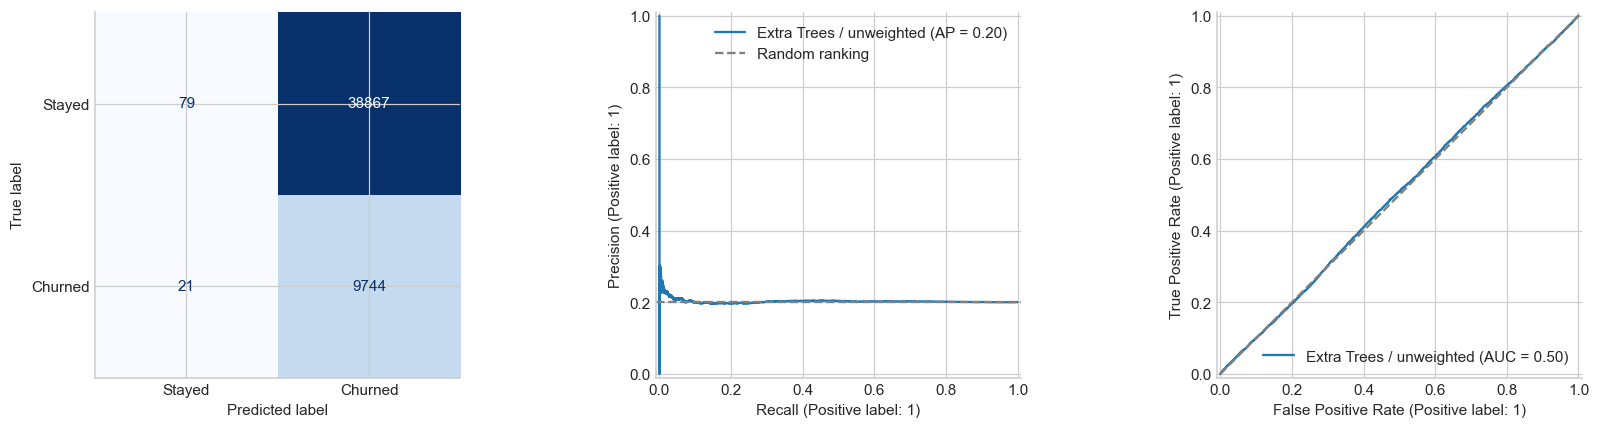

,lower_95,upper_95
AP minus prevalence,-0.00120,0.00643
AUC minus 0.5,-0.00298,0.01055


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions,
    display_labels=['Stayed', 'Churned'], cmap='Blues', colorbar=False, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[1], name=selected_name)
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label='Random ranking')
axes[1].legend()
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[2], name=selected_name)
axes[2].plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.tight_layout(); plt.show()
display(ranking_uncertainty(y_test, test_probabilities).round(5))


## 11. Measured findings
Unweighted Extra Trees wins training CV AP (**0.20330**, fold SD **0.00171**), versus baseline **0.20048**. This small gain does not replicate on validation: **AP 0.20068** versus prevalence **0.20049**, **ROC-AUC 0.49562**. Full-training AP **0.40586** falls to **0.20068** on validation, a **0.20519** gap. Its CV training/held-fold AP gap is **0.19901**, consistent with substantial overfitting.

| Family | Unweighted CV AP | Balanced CV AP | Unweighted validation AP | Balanced validation AP |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.20152 | 0.20153 | 0.19912 | 0.19912 |
| Random Forest | 0.20132 | 0.20109 | 0.20170 | 0.20196 |
| Extra Trees | 0.20330 | 0.20324 | 0.20068 | 0.20147 |
| HistGradientBoosting | 0.20037 | 0.20026 | 0.20356 | 0.20425 |

Higher validation AP for a different family does not trigger reselection after the predeclared CV decision. Weighting has no consistent ranking advantage. The logistic raw/engineered comparison at C=0.1 changes CV AP by less than 0.00004.

Validation F1 tuning contacts **99.83%**, with precision **0.20064**, recall **0.99908**, F1 **0.33417**, and accuracy **0.20178**. Contacting everyone has F1 **0.33401**; majority-class accuracy is **0.79951**. Exact 10% and 20% outreach yield precision **0.20341 / 0.20394**, recall **0.10147 / 0.20346**, and lift **1.01456 / 1.01722**. These tiny lifts sit near random selection.

Validation paired-bootstrap 95% intervals are **[-0.00339, 0.00410]** for AP minus prevalence and **[-0.01124, 0.00191]** for AUC minus 0.5. Both include zero. Random-ranking simulation places AP roughly between **0.19673 and 0.20410** and top-10% precision between **0.19027 and 0.20978**. No dependable baseline-beating targeting signal is demonstrated.

The descriptive frozen audit on the **previously inspected test** has AP **0.20305** and AUC **0.50403**, top-10% lift **0.99930**, and top-20% lift **0.98456**. These are not fresh final performance claims and are not used to make decisions. The original historical random-forest audit had AUC 0.4999 and AP 0.2001; differences between inspected-test experiments must not guide further tuning.

Quality findings: no original missing entries or duplicate rows; **6,713 / 7,375 / 6,050** negative call/SMS/data readings; each of six cities spans all 28 states. Training numeric standardized class-mean differences are below **0.011**. Source investigation is warranted; synthetic origin is not established. Permutation importance on a 5,000-customer validation subset is exploratory and unstable; it does not establish reliable business drivers.


## 12. Conclusion and data needed
Read the measured CV, validation, baseline simulation and uncertainty tables above. Near-random ranking despite more flexible models is evidence that these recorded inputs do not support dependable churn targeting under this protocol. High majority accuracy and F1 from contacting everyone do not establish useful ranking. Differences after this small search still carry selection uncertainty.

No dataset provenance establishes synthetic origin. Broad, similar feature distributions and city/state inconsistencies warrant source investigation, not a synthetic-data claim. Binary encoding is verified; the interpretation `1 = churn` follows the existing project convention and needs confirmation from the data owner. The outcome event, time window and feature availability remain undocumented.

Collect observation timestamps, a precisely defined future churn event/window, and measurements strictly before that window. Useful candidates include contracts/renewals, billing/payment changes, complaints, outages, service quality, and longitudinal usage in separately documented units and windows. Tenure can be calculated only once observation dates are supplied. Collect a new independent temporal cohort and evaluate retention interventions experimentally. Do not force better metrics through leakage or repeated test selection.
